Linear interpolation:
MAE: 0.00115346
RMSE: 0.00413643
maximum_absolute_error: 0.04299596

Cubic spline interpolation:
MAE: 0.00015406
RMSE: 0.00110457
maximum_absolute_error: 0.01727057


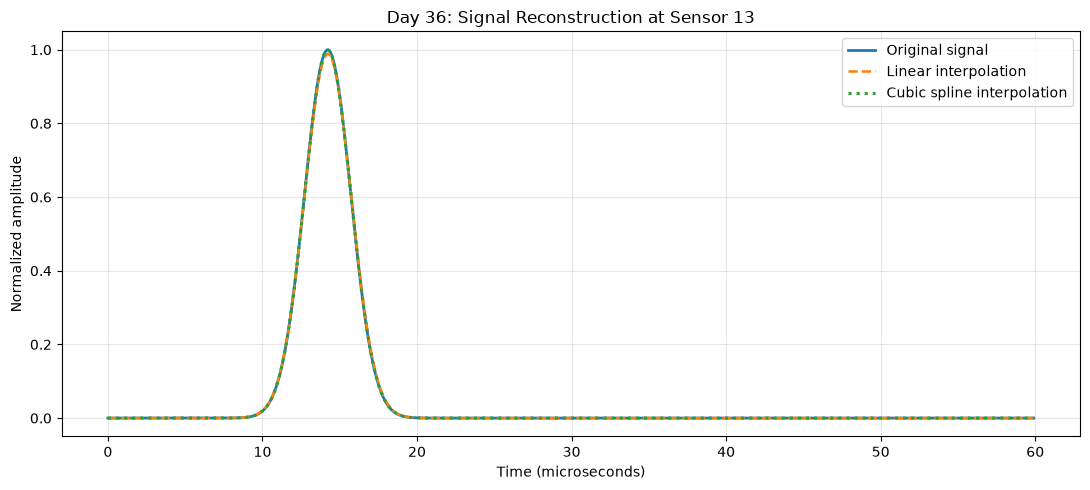

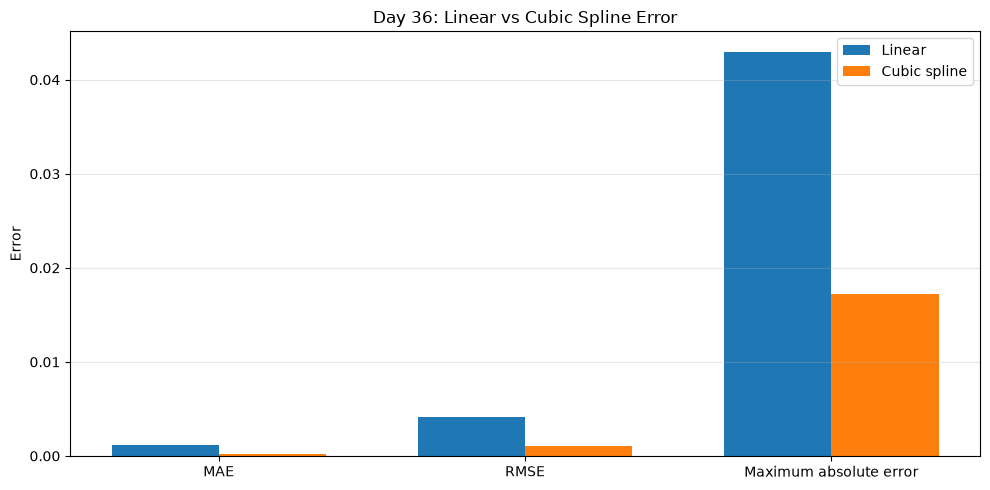


Day 36 completed.
Signal comparison saved to: ..\outputs\day36_spline_signal_comparison.png
Error comparison saved to: ..\outputs\day36_spline_error_comparison.png
Results saved to: ..\outputs\day36_spline_results.json


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# ==========================================
# Day 36: Cubic Spline Interpolation
# ==========================================

# 1. Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

time = np.arange(num_samples) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# 3. Generate original synthetic signals
signals_full = np.zeros((num_sensors, num_samples))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt(
        (sx - source_x)**2 + source_y**2
    )
    arrival_time = distance / c

    signals_full[i, :] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 4. Simulate periodic sensor failures
inactive_indices = np.array(
    [1, 5, 9, 13, 17, 21, 25, 29]
)

active_mask = np.ones(num_sensors, dtype=bool)
active_mask[inactive_indices] = False

active_x = sensor_x[active_mask]
active_signals = signals_full[active_mask, :]

# 5. Linear interpolation baseline
linear_interpolator = interp1d(
    active_x,
    active_signals,
    kind="linear",
    axis=0,
    bounds_error=False,
    fill_value="extrapolate"
)

signals_linear = signals_full.copy()
signals_linear[inactive_indices, :] = linear_interpolator(
    sensor_x[inactive_indices]
)

# 6. Cubic spline interpolation
# Interpolate across sensor positions for every time sample.
spline_interpolator = CubicSpline(
    active_x,
    active_signals,
    axis=0,
    bc_type="natural",
    extrapolate=True
)

signals_spline = signals_full.copy()
signals_spline[inactive_indices, :] = spline_interpolator(
    sensor_x[inactive_indices]
)

# 7. Evaluate only the inactive sensor signals
original_missing = signals_full[inactive_indices, :]

linear_error = (
    signals_linear[inactive_indices, :] - original_missing
)
spline_error = (
    signals_spline[inactive_indices, :] - original_missing
)

def calculate_metrics(error):
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "maximum_absolute_error": float(np.max(np.abs(error)))
    }

linear_metrics = calculate_metrics(linear_error)
spline_metrics = calculate_metrics(spline_error)

print("Linear interpolation:")
for metric, value in linear_metrics.items():
    print(f"{metric}: {value:.8f}")

print("\nCubic spline interpolation:")
for metric, value in spline_metrics.items():
    print(f"{metric}: {value:.8f}")

# 8. Plot original, linear, and spline signals
sensor_to_plot = 13

plt.figure(figsize=(11, 5))

plt.plot(
    time * 1e6,
    signals_full[sensor_to_plot],
    label="Original signal",
    linewidth=2
)

plt.plot(
    time * 1e6,
    signals_linear[sensor_to_plot],
    "--",
    label="Linear interpolation",
    linewidth=1.8
)

plt.plot(
    time * 1e6,
    signals_spline[sensor_to_plot],
    ":",
    label="Cubic spline interpolation",
    linewidth=2.2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Normalized amplitude")
plt.title(f"Day 36: Signal Reconstruction at Sensor {sensor_to_plot}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day36_spline_signal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Plot error comparison
metric_names = ["MAE", "RMSE", "maximum_absolute_error"]

linear_values = [
    linear_metrics[name] for name in metric_names
]
spline_values = [
    spline_metrics[name] for name in metric_names
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    linear_values,
    width,
    label="Linear"
)

ax.bar(
    x + width / 2,
    spline_values,
    width,
    label="Cubic spline"
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["MAE", "RMSE", "Maximum absolute error"]
)
ax.set_ylabel("Error")
ax.set_title("Day 36: Linear vs Cubic Spline Error")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "day36_spline_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 10. Save results
results = {
    "day": 36,
    "num_sensors": num_sensors,
    "num_samples": num_samples,
    "inactive_sensor_indices": inactive_indices.tolist(),
    "missing_sensor_percentage": float(
        100 * len(inactive_indices) / num_sensors
    ),
    "evaluation_region": "inactive sensor signals only",
    "linear_interpolation": linear_metrics,
    "cubic_spline_interpolation": spline_metrics,
    "spline_boundary_condition": "natural"
}

results_path = output_dir / "day36_spline_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nDay 36 completed.")
print(f"Signal comparison saved to: {output_dir / 'day36_spline_signal_comparison.png'}")
print(f"Error comparison saved to: {output_dir / 'day36_spline_error_comparison.png'}")
print(f"Results saved to: {results_path}")
